# Dataset exploration

### Code

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from random import random
import pandas as pd
from keras.preprocessing.image import img_to_array, load_img
# from tensorflow.keras.utils import save_img
import os


from handspell.data_exploration import *

## A. Cropped Images of Letters (Labeled)

### A01 - ASL MNIST (Kaggle: ([link](https://www.kaggle.com/datasets/datamunge/sign-language-mnist?select=sign_mnist_test))

- 28x28 grey-scaled images (1 channel) already flattened
- 24 classes of letters (excluding J and Z which require motion)
- 27,455 + 7,172 images (pre-split into train and test)
- result of applying a pre-processing pipeline to 1,704 color images (3 channels) - based on ImageMagick:
  - crop hands only
  - grey-scale
  - resize
  - data augmentation
    - filters ('Mitchell', 'Robidoux', 'Catrom', 'Spline', 'Hermite')
    - 5% random pixelation
    - +/- 15% brightness/contrast
    - 3 degrees rotation)

In [2]:
infos_df, dataset_path = get_a01_dataset_infos()

print_dataset_infos(infos_df)

infos_df.head()

Dataset: A01_kaggle_aslmnist
- 34627 images
- 24 labels (['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y'])
- images 28x28 pixels
- All greyscale images (1 channel)


,letter,image_path,test,dataset,width,height,channels,hand_cropped,preprocessed
0,D,../data/raw_data/A01_kaggle_aslmnist/train/D/D...,False,A01_kaggle_aslmnist,28,28,1,True,True
1,G,../data/raw_data/A01_kaggle_aslmnist/train/G/G...,False,A01_kaggle_aslmnist,28,28,1,True,True
2,C,../data/raw_data/A01_kaggle_aslmnist/train/C/C...,False,A01_kaggle_aslmnist,28,28,1,True,True
3,C,../data/raw_data/A01_kaggle_aslmnist/train/C/C...,False,A01_kaggle_aslmnist,28,28,1,True,True
4,N,../data/raw_data/A01_kaggle_aslmnist/train/N/N...,False,A01_kaggle_aslmnist,28,28,1,True,True


In [3]:
# Count number of images per letter
# No J, no Z
infos_df.groupby(["test", "letter"])[["image_path"]].count()

image_path
test  letter            
False A             1126
      B             1010
      C             1144
      D             1196
      E              957
      F             1204
      G             1090
      H             1013
      I             1162
      K             1114
      L             1241
      M             1055
      N             1151
      O             1196
      P             1088
      Q             1279
      R             1294
      S             1199
      T             1186
      U             1161
      V             1082
      W             1225
      X             1164
      Y             1118
True  A              331
      B              432
      C              310
      D              245
      E              498
      F              247
      G              348
      H              436
      I              288
      K              331
      L              209
      M              394
      N              291
      O              246
      P              347
      Q              164
      R              144
      S              246
      T              248
      U              266
      V              346
      W              206
      X              267
      Y              332

A 1457
B 1442
C 1454
D 1441
E 1455
F 1451
G 1438
H 1449
I 1450
J 0
K 1445
L 1450
M 1449
N 1442
O 1442
P 1435
Q 1443
R 1438
S 1445
T 1434
U 1427
V 1428
W 1431
X 1431
Y 1450
Z 0


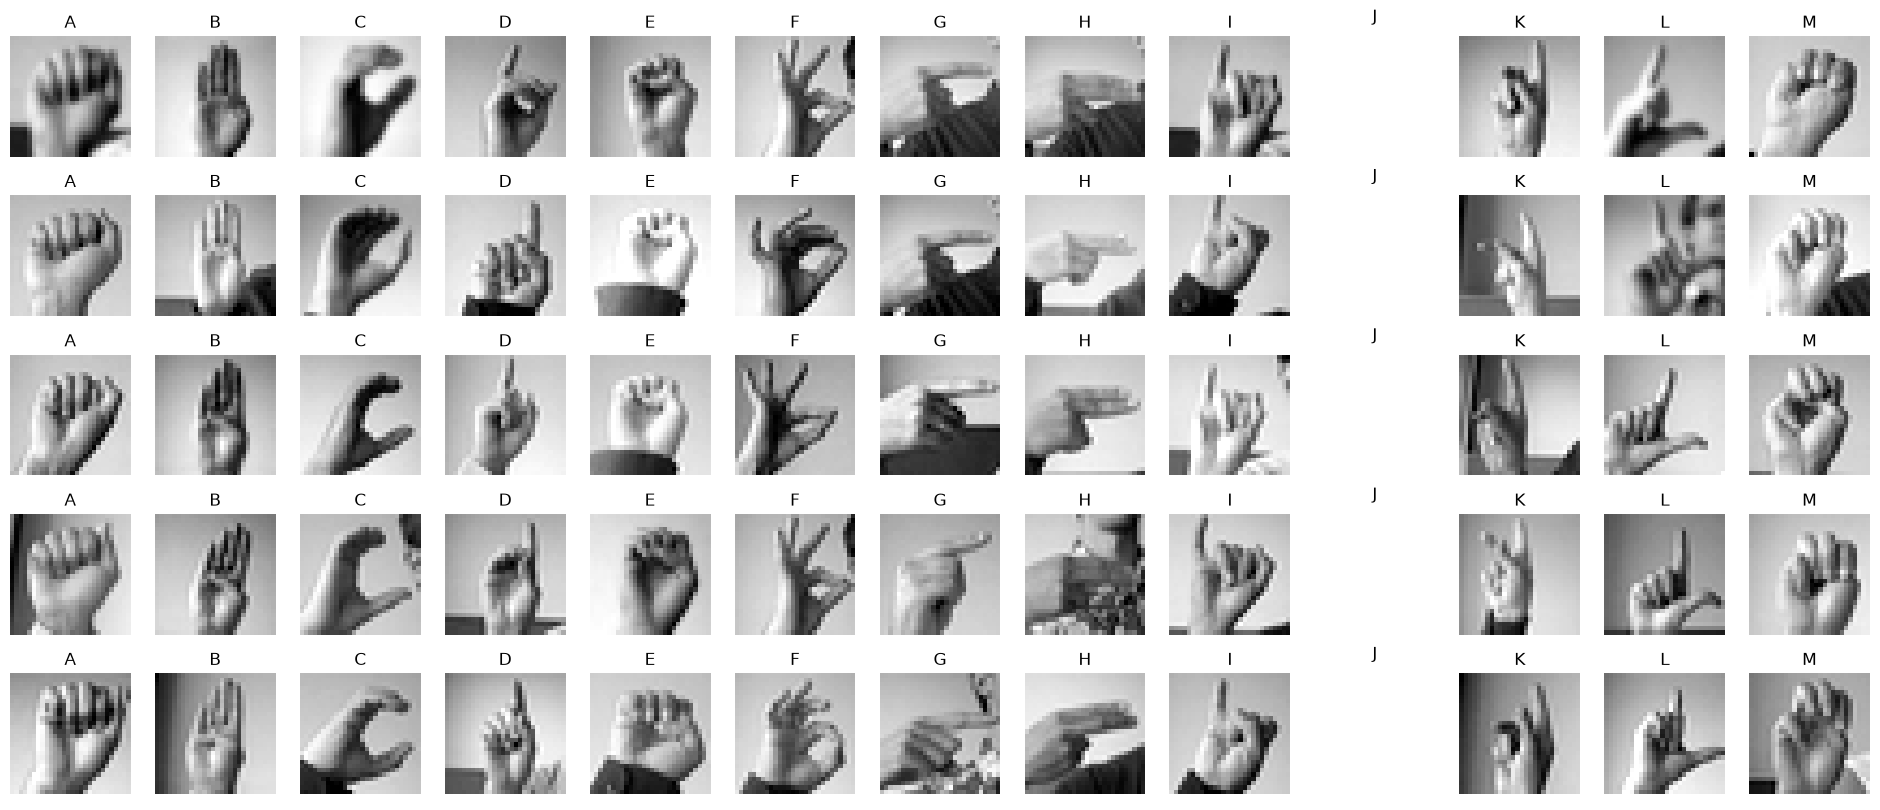

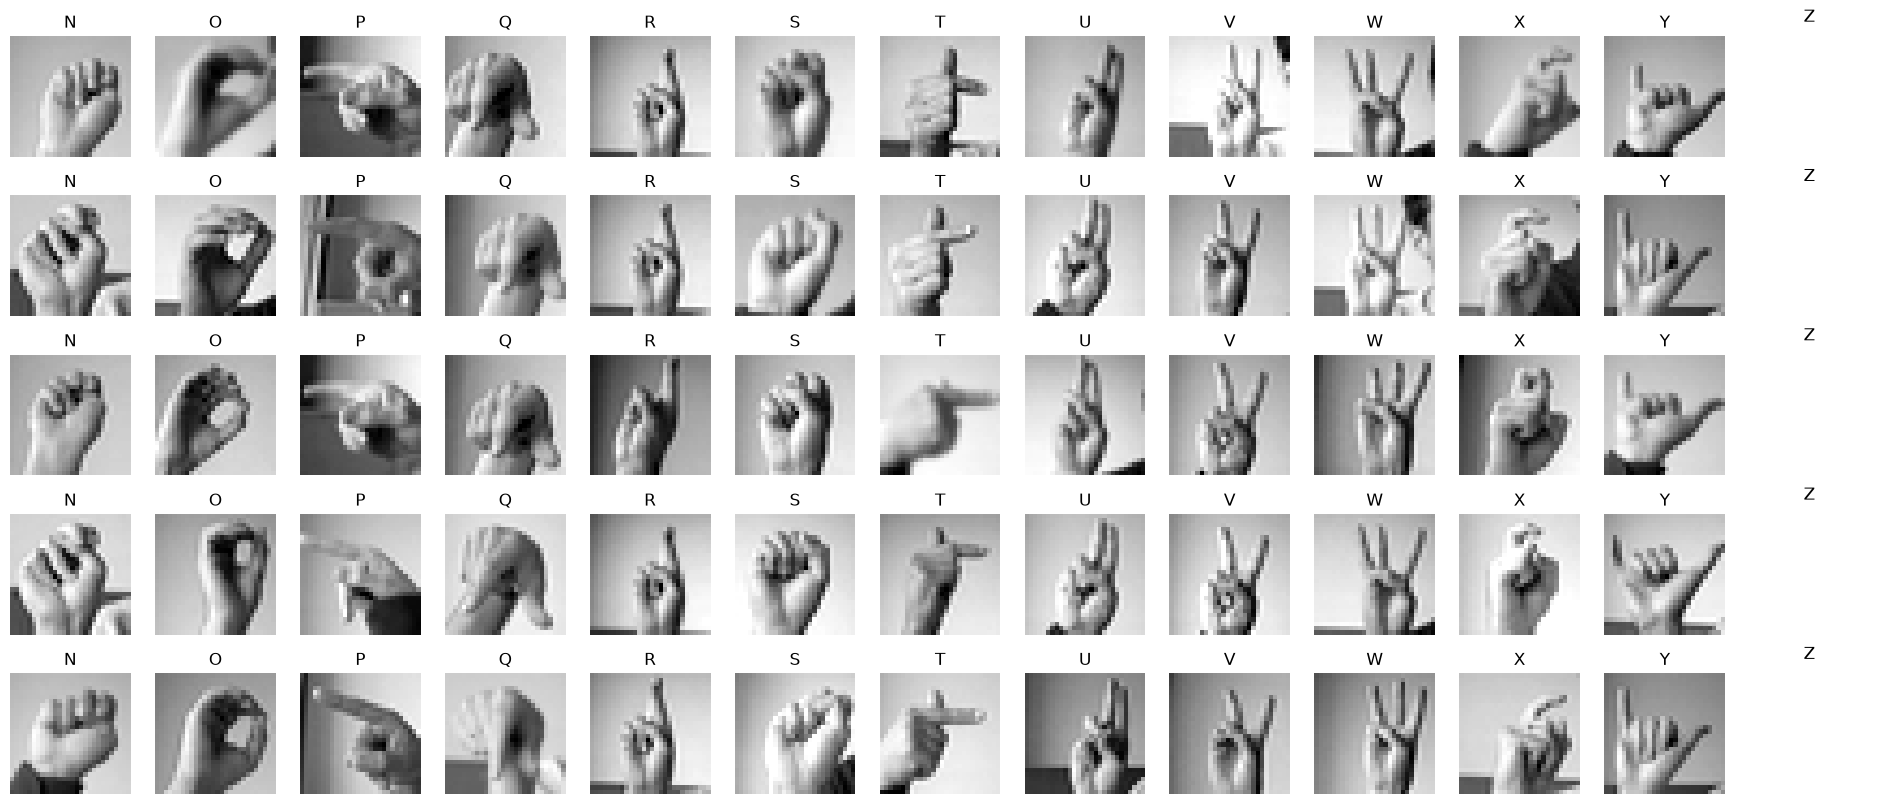

In [4]:
f1, f2 = plot_example_images(infos_df, get_image_from_info_row,
                    n_examples=5, figsize=(24, 10))
f1.savefig("../data/raw_data/A01_kaggle_aslmnist/examples_A_M.png")
f2.savefig("../data/raw_data/A01_kaggle_aslmnist/examples_N_Z.png")

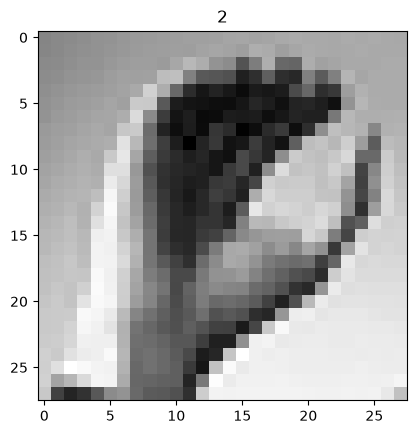

In [5]:
# Represent row as image
train_df = pd.read_csv(f"../data/raw_data/{A01_LABEL}/sign_mnist_train.csv")

img_2828 = get_image_from_row_a01(
    train_df.sample().iloc[0],
    plot=True)

In [6]:
get_image_from_info_row(infos_df.sample().iloc[0])

In [ ]:
# Save an image from a numpy array
# from tensorflow.keras.utils import save_img
# save_img("../data/preprocessed/test.jpg", img_2828, quality=100)

### A02 - Sign Language Gesture Images Dataset ([link](https://www.kaggle.com/datasets/ahmedkhanak1995/sign-language-gesture-images-dataset))

In [8]:
from handspell.data_exploration import get_a02_dataset_infos

infos_df, dataset_path, exceptions = get_a02_dataset_infos()

infos_df.head()

Saving Data Description: ../data/raw_data/A02_kaggle_ahmedkhanak/dataset_infos.csv


,dataset,label,letter,image_name,width,height,channels,image_path
0,A02_kaggle_ahmedkhanak,R,R,63.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...
1,A02_kaggle_ahmedkhanak,R,R,823.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...
2,A02_kaggle_ahmedkhanak,R,R,1409.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...
3,A02_kaggle_ahmedkhanak,R,R,189.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...
4,A02_kaggle_ahmedkhanak,R,R,77.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...


In [9]:
infos_df.head()

,dataset,label,letter,image_name,width,height,channels,image_path
0,A02_kaggle_ahmedkhanak,R,R,63.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...
1,A02_kaggle_ahmedkhanak,R,R,823.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...
2,A02_kaggle_ahmedkhanak,R,R,1409.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...
3,A02_kaggle_ahmedkhanak,R,R,189.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...
4,A02_kaggle_ahmedkhanak,R,R,77.jpg,50,50,3,../data/raw_data/A02_kaggle_ahmedkhanak/Gestur...


## B. Non-cropped Static Images of Letters (Labeled)

In [11]:
infos_df, dataset_path = get_b01_dataset_infos()

# print_dataset_infos(infos_df)

infos_df.head()

""


In [ ]:
infos_df.groupby(["person", "letter"])[["image_path"]].count().head(50)

image_path
person  letter            
user_10 A               10
        B               10
        C               10
        D               10
        E               10
        F               10
        G               10
        H               10
        I               10
        K               10
        L               10
        M               10
        N               10
        O               10
        P               10
        Q               10
        R               10
        S               10
        T               10
        U               10
        V               10
        W               10
        X               10
        Y               10
user_3  A               10
        B               10
        C               10
        D               10
        E               10
        F               10
        G               10
        H               10
        I               10
        K               10
        L               10
        M               10
        N               10
        O               10
        P               10
        Q               10
        R               10
        S               10
        T               10
        U               10
        V               10
        W               10
        X               10
        Y               10
user_4  A               10
        B               10

A 70
B 70
C 70
D 70
E 70
F 70
G 70
H 70
I 70
J 0
K 70
L 70
M 70
N 70
O 70
P 70
Q 70
R 70
S 70
T 70
U 70
V 70
W 70
X 70
Y 70
Z 0


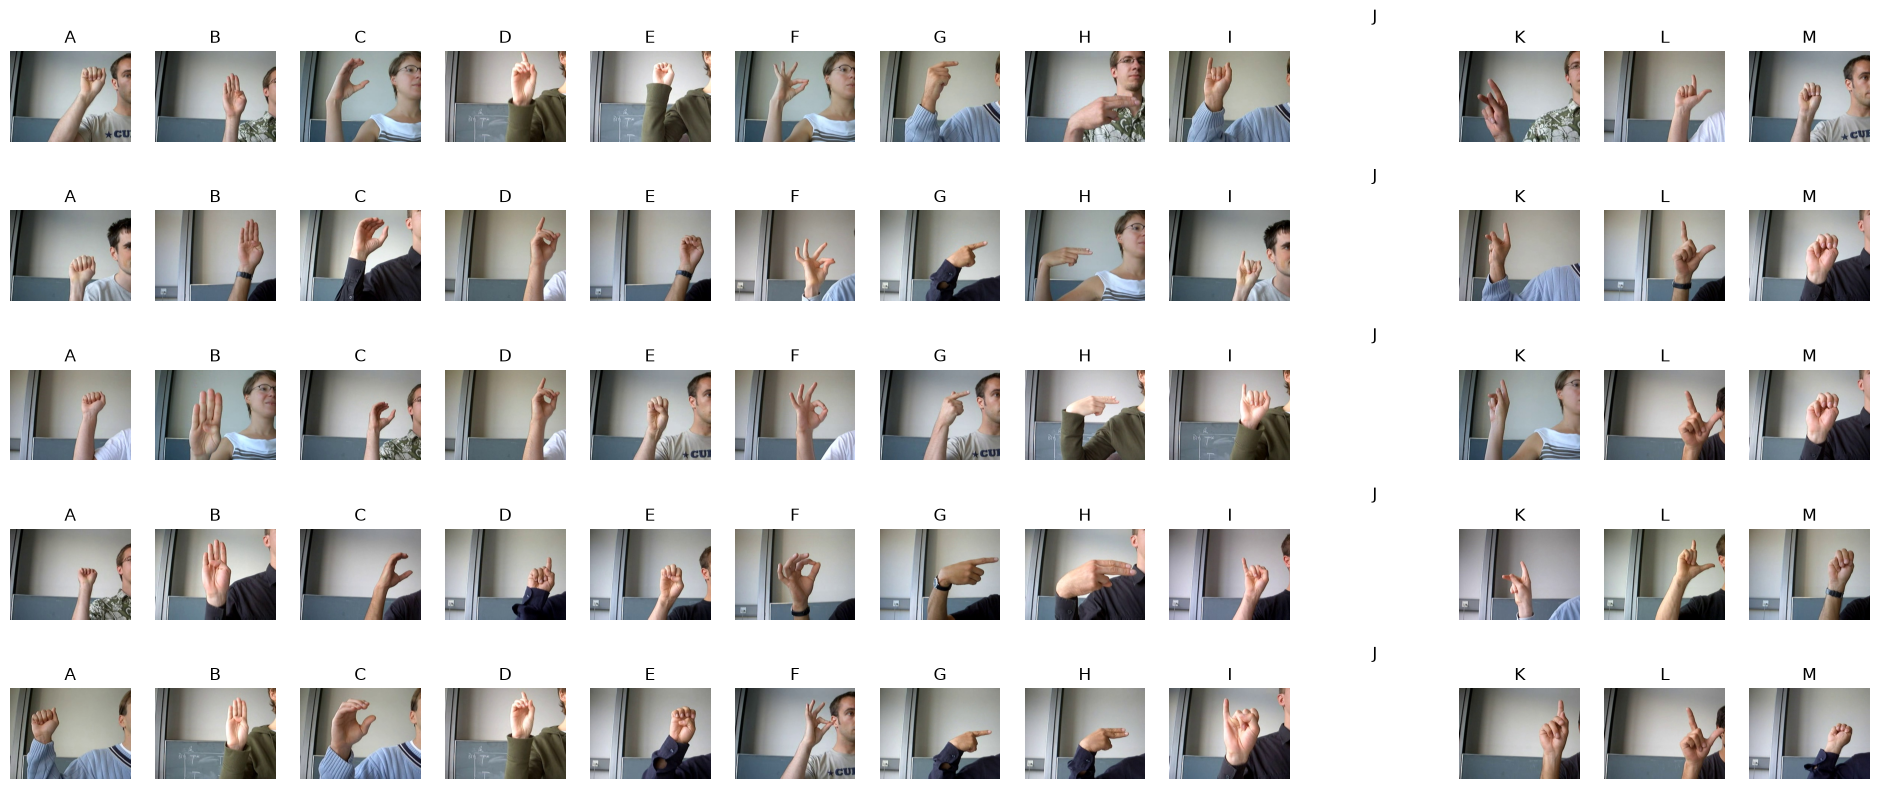

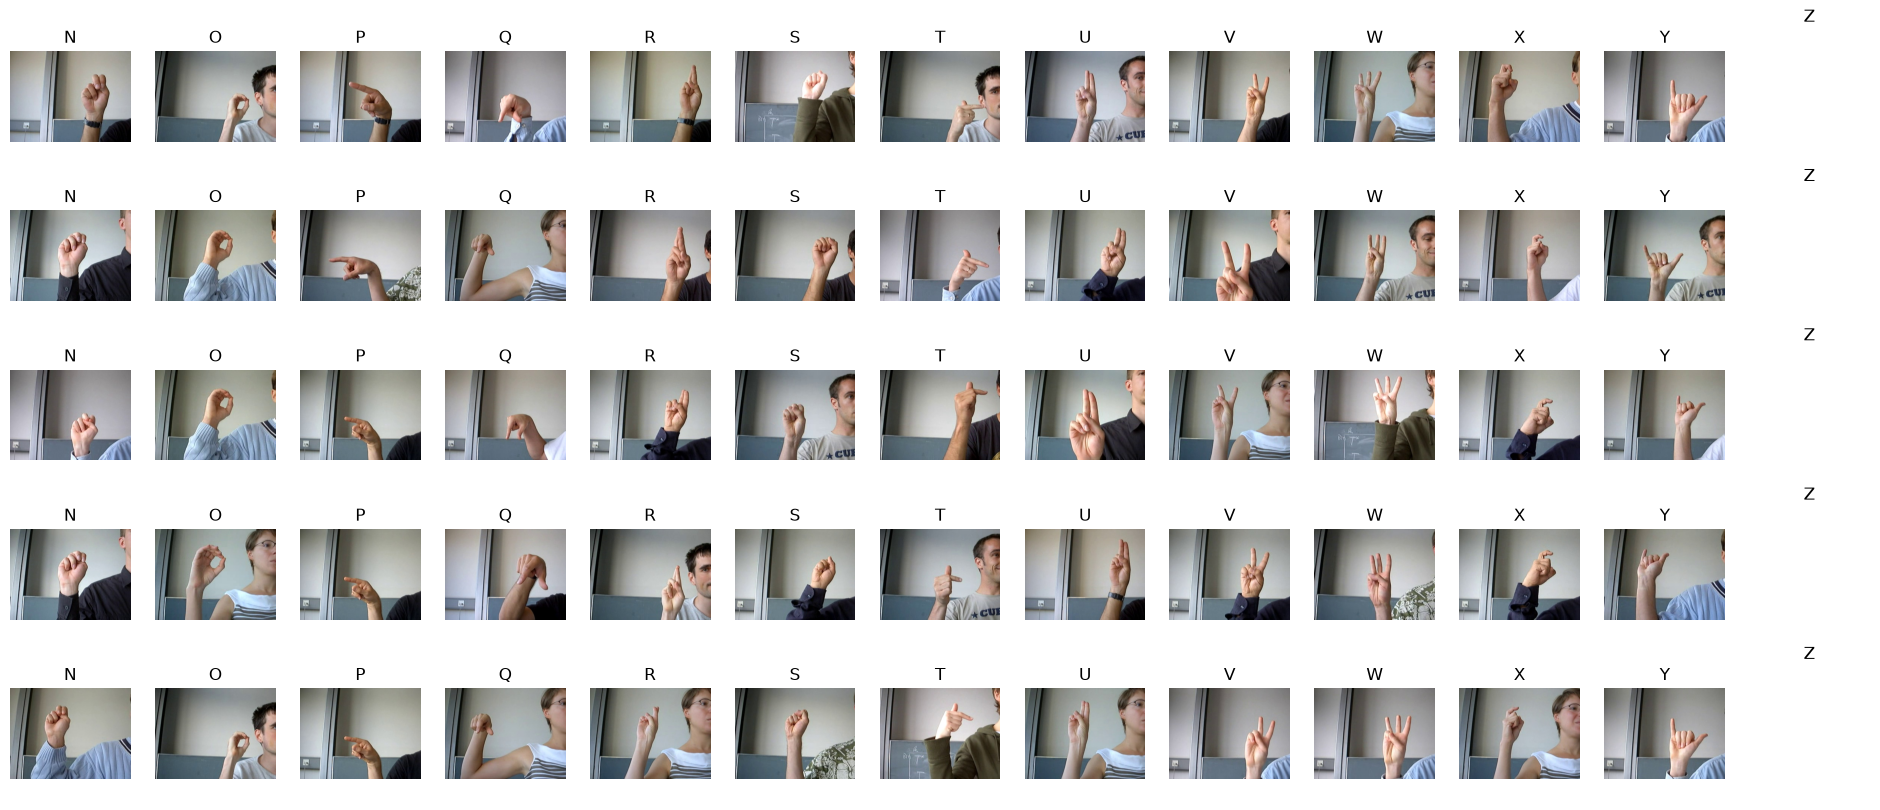

In [ ]:
# chart with n random images per letter

plot_example_images(infos_df, get_image_from_info_row,
                    n_examples=5, figsize=(24, 10))

In [ ]:
# Image sizes
infos_df[["width", "height"]].describe()

,width,height
count,1680.0,1680.0
mean,320.0,240.0
std,0.0,0.0
min,320.0,240.0
25%,320.0,240.0
50%,320.0,240.0
75%,320.0,240.0
max,320.0,240.0


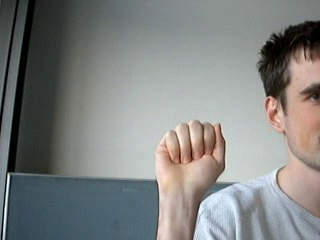

In [ ]:
# Load one image
img = load_img(f"../data/raw_data/B01_original_aslmnist/user_6/A0.jpg")
img

In [ ]:
# Get image size and number of channels from loading it
get_image_size_and_channels(f"../data/raw_data/B01_original_aslmnist/user_6/A0.jpg")

{'width': 320, 'height': 240, 'channels': 3}